In [1]:
import requests
import pandas as pd

BASE = "https://api.openf1.org/v1"

def get(endpoint, **params):
    r = requests.get(f"{BASE}/{endpoint}", params=params, timeout = 30)
    r.raise_for_status()
    return pd.DataFrame(r.json())

In [2]:
sessions = get("sessions", year = 2026, session_name = "Practice 2")
sessions[["session_key", "location", "date_start"]]

#sessions - table with one row for every session

las_vegas = sessions[sessions["location"] == "Las Vegas"]
SESSION_KEY = las_vegas["session_key"].iloc[0]

In [3]:
laps = get("laps", session_key = SESSION_KEY)
stints = get("stints", session_key = SESSION_KEY)
print(laps.shape, stints.shape)
laps.head()

(413, 16) (72, 8)


,meeting_key,session_key,driver_number,lap_number,date_start,duration_sector_1,duration_sector_2,duration_sector_3,i1_speed,i2_speed,is_pit_out_lap,lap_duration,segments_sector_1,segments_sector_2,segments_sector_3,st_speed
0,1300,11414,41,1,NaN,NaN,52.726,60.477,116.0,162.0,True,NaN,"[2064, 2064, 2049, 2049, 2049, 2049]","[2049, 2049, 2049, 2049, 2049, 2049, 2049]","[2049, 2051, 2051, 2051, 2051, 2051, 2051, 205...",164.0
1,1300,11414,81,1,2026-11-20T04:01:31.674000+00:00,NaN,46.228,46.338,142.0,190.0,True,NaN,"[2064, 2064, 2049, 2049, 2049, 2049]","[2049, 2049, 2049, 2051, 2051, 2049, 2049]","[2051, 2051, 2051, 2049, 2049, 2051, 2051, 205...",156.0
2,1300,11414,30,1,2026-11-20T04:01:36.483000+00:00,NaN,47.325,53.913,141.0,185.0,True,NaN,"[2064, 2064, 2049, 2049, 2049, 2049]","[2049, 2049, 2049, 2049, 2049, 2049, 2049]","[2049, 2049, 2049, 2049, 2049, 2049, 2049, 204...",174.0
3,1300,11414,16,1,2026-11-20T04:01:48.250000+00:00,NaN,45.999,46.995,143.0,186.0,True,NaN,"[2064, 2064, 2049, 2049, 2049, 2049]","[2049, 2051, 2051, 2049, 2049, 2049, 2049]","[2049, 2049, 2049, 2051, 2051, 2049, 2049, 204...",183.0
4,1300,11414,23,1,2026-11-20T04:02:15.839000+00:00,NaN,45.315,46.680,134.0,186.0,True,NaN,"[2064, 2064, 2049, 2049, 2049, 2049]","[2049, 2049, 2049, 2049, 2049, 2049, 2051]","[2049, 2051, 2051, 2049, 2049, 2049, 2049, 204...",167.0


In [4]:
laps_per_driver = laps.groupby("driver_number").size().sort_values(ascending = False)
laps_per_driver

driver_number
16    28
44    26
81    24
12    23
63    23
18    23
23    23
1     22
87    22
14    21
6     20
51    20
11    17
10    16
27    16
5     15
43    15
77    14
41    13
30    12
55    11
3      9
dtype: int64

In [5]:
stints["compound"].value_counts()

compound
INTERMEDIATE    47
WET             25
Name: count, dtype: int64

Las Vegas FP2 was run entirely on INTERMEDIATE/WET tyres, so it can not be used for dry race pace.

In [6]:
stints_per_pilot = stints.groupby("driver_number").size()
stints_per_pilot.value_counts()

3    10
4     7
2     4
6     1
Name: count, dtype: int64

In [7]:
no_time = laps[laps["lap_duration"].isna()]
print(len(no_time))
display(no_time[["driver_number", "lap_number", "is_pit_out_lap"]])

no_time["is_pit_out_lap"].value_counts()

37


,driver_number,lap_number,is_pit_out_lap
0,41,1,True
1,81,1,True
2,30,1,True
3,16,1,True
4,23,1,True
5,44,1,True
6,63,1,True
7,1,1,True
8,18,1,True
9,12,1,True


is_pit_out_lap
True     22
False    15
Name: count, dtype: int64

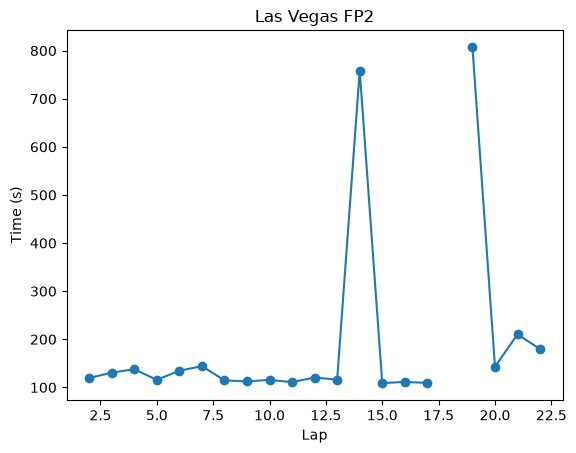

In [8]:
import matplotlib.pyplot as plt

d = laps[laps["driver_number"] == 1]   
plt.plot(d["lap_number"], d["lap_duration"], "o-")
plt.xlabel("Lap"); plt.ylabel("Time (s)"); plt.title("Las Vegas FP2")
plt.show()

I need to implement an automated rule for "slow" laps. 

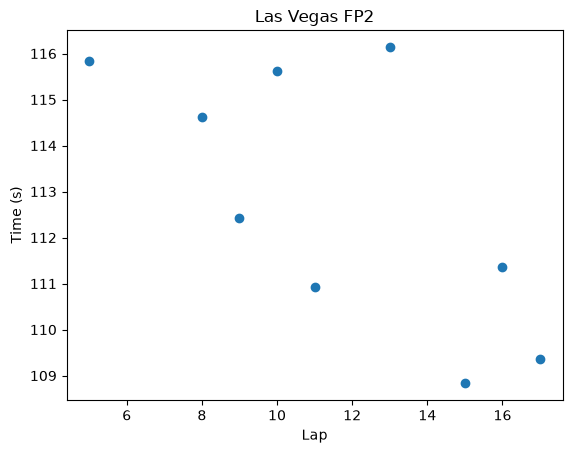

In [9]:
d = laps[laps["driver_number"] == 1] 
best = d["lap_duration"].min()
clean = d[d["lap_duration"] < 1.07 * best]

plt.plot(clean["lap_number"], clean["lap_duration"], "o")
plt.xlabel("Lap"); plt.ylabel("Time (s)"); plt.title("Las Vegas FP2")
plt.show()

Because the wet track became dry, the first stint was completely eliminated, which is why we will calculate 1.07*Best per stint.